### Bike Rental Analysis and Daily Demand Prediction

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from ydata_profiling import ProfileReport
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## Load both datasets

In [6]:
day = pd.read_csv(r"C:\Users\Hemanth\Downloads\PRCP-1018-BikeRental\Data\day.csv")
hour = pd.read_csv(r"C:\Users\Hemanth\Downloads\PRCP-1018-BikeRental\Data\hour.csv")

In [7]:
print("Day shape :", day.shape)
print("Hour shape:", hour.shape)

Day shape : (731, 16)
Hour shape: (17379, 17)


In [8]:
day.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [9]:
hour.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## Data understanding and quality checks

In [11]:
print(day.columns.tolist())
day.info()

['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    i

In [12]:
print(hour.columns.tolist())
hour.info()

['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 n

In [13]:
print("Missing values in day :", day.isnull().sum().sum())
print("Missing values in hour:", hour.isnull().sum().sum())
print("Duplicates in day :", day.duplicated().sum())
print("Duplicates in hour:", hour.duplicated().sum())

Missing values in day : 0
Missing values in hour: 0
Duplicates in day : 0
Duplicates in hour: 0


In [14]:
day['dteday'] = pd.to_datetime(day['dteday'])
hour['dteday'] = pd.to_datetime(hour['dteday'])

hourly_total = hour.groupby('dteday')['cnt'].sum()
print("Hour file sums to day file:", (hourly_total.values == day['cnt'].values).all())

print("casual + registered = cnt:", (day['cnt'] == day['casual'] + day['registered']).all())

print("Min hours in a day:", hour.groupby('dteday').size().min())
print("Max hours in a day:", hour.groupby('dteday').size().max())

Hour file sums to day file: True
casual + registered = cnt: True
Min hours in a day: 1
Max hours in a day: 24


In [15]:
profile_day = ProfileReport(day, title="Bike Sharing: Daily Data Profile", explorative=True)
profile_hour = ProfileReport(hour, title="Bike Sharing: Hourly Data Profile", minimal=True)

In [16]:
profile_day

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 16/16 [00:00<00:00, 274.20it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [17]:
profile_hour

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 17/17 [00:00<00:00, 779.58it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

## Check strange values

In [18]:
print("Days with humidity = 0 :", (day['hum'] == 0).sum())
print("Hours with humidity = 0:", (hour['hum'] == 0).sum())

print("\nWeather situation counts (day):")
print(day['weathersit'].value_counts())
print("\nWeather situation counts (hour):")
print(hour['weathersit'].value_counts())

Days with humidity = 0 : 1
Hours with humidity = 0: 22

Weather situation counts (day):
weathersit
1    463
2    247
3     21
Name: count, dtype: int64

Weather situation counts (hour):
weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64


In [19]:
# Replace the impossible humidity (0) in the daily data with the median humidity
median_hum = day.loc[day['hum'] > 0, 'hum'].median()
day.loc[day['hum'] == 0, 'hum'] = median_hum
print("Fixed. New minimum humidity:", day['hum'].min())

Fixed. New minimum humidity: 0.187917


In [20]:
day['temp_c'] = day['temp'] * 47 - 8        
day['hum_pct'] = day['hum'] * 100
day['wind_kmh'] = day['windspeed'] * 67

day[['temp_c', 'hum_pct', 'wind_kmh', 'cnt']].describe()

,temp_c,hum_pct,wind_kmh,cnt
count,731.000000,731.000000,731.000000,731.000000
mean,15.283085,62.875191,12.762576,4504.348837
std,8.603397,14.051776,5.192357,1937.211452
min,-5.220871,18.791700,1.500244,22.000000
25%,7.842925,52.104150,9.041650,3152.000000
50%,15.421651,62.708350,12.125325,4548.000000
75%,22.804575,73.020850,15.625371,5956.000000
max,32.498349,97.250000,34.000021,8714.000000


## EDA

count     731.000000
mean     4504.348837
std      1937.211452
min        22.000000
25%      3152.000000
50%      4548.000000
75%      5956.000000
max      8714.000000
Name: cnt, dtype: float64
Skewness: -0.04735278011900183


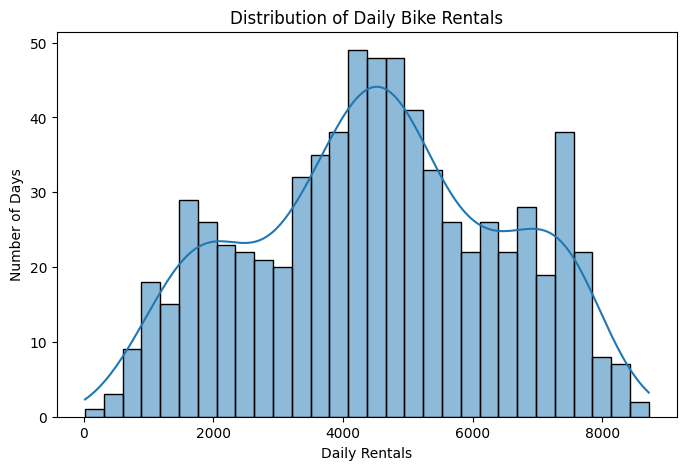

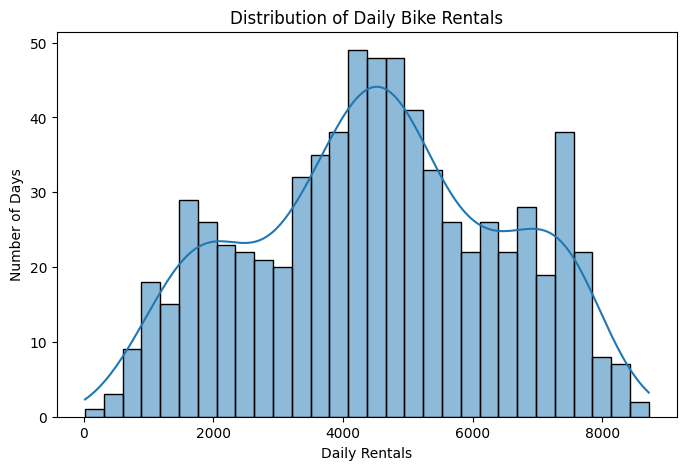

In [23]:
print(day['cnt'].describe())
print("Skewness:", day['cnt'].skew())

plt.figure(figsize=(8, 5))
sns.histplot(data=day, x='cnt', bins=30, kde=True)
plt.title("Distribution of Daily Bike Rentals")
plt.xlabel("Daily Rentals")
plt.ylabel("Number of Days")
plt.show()

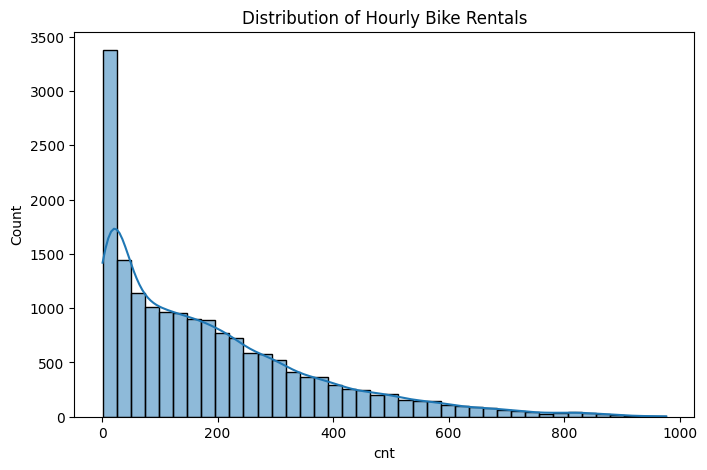

Hourly skewness: 1.2774116037490573


In [24]:
plt.figure(figsize=(8, 5))
sns.histplot(data=hour, x='cnt', bins=40, kde=True)
plt.title("Distribution of Hourly Bike Rentals")
plt.show()
print("Hourly skewness:", hour['cnt'].skew())

year
2011    3405.761644
2012    5599.934426
Name: cnt, dtype: float64


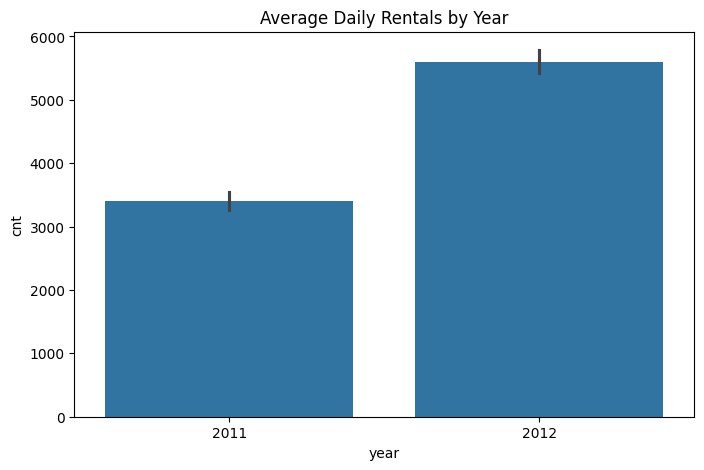

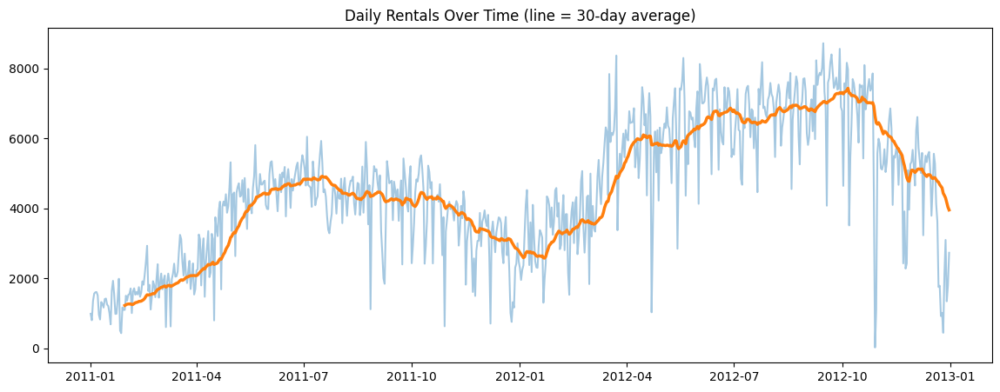

In [25]:
day['year'] = day['yr'].map({0: 2011, 1: 2012})

print(day.groupby('year')['cnt'].mean())

plt.figure(figsize=(8, 5))
sns.barplot(data=day, x='year', y='cnt')
plt.title("Average Daily Rentals by Year")
plt.show()

plt.figure(figsize=(14, 5))
plt.plot(day['dteday'], day['cnt'], alpha=0.4)
plt.plot(day['dteday'], day['cnt'].rolling(30).mean(), linewidth=2.5)
plt.title("Daily Rentals Over Time (line = 30-day average)")
plt.show()

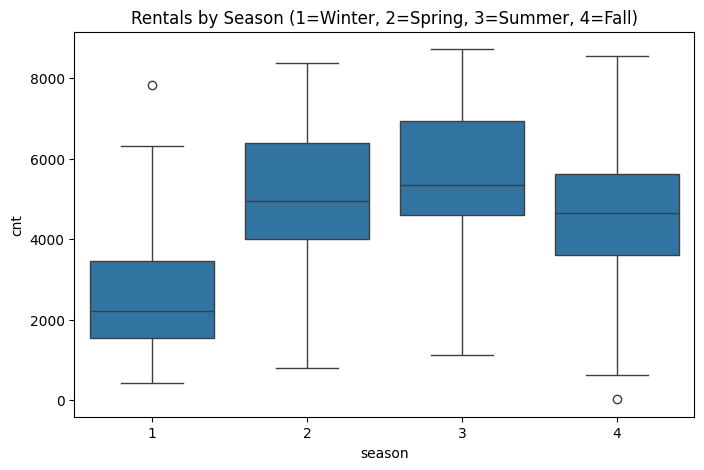

season
1    2604.0
2    4992.0
3    5644.0
4    4728.0
Name: cnt, dtype: float64


In [26]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=day, x='season', y='cnt')
plt.title("Rentals by Season (1=Winter, 2=Spring, 3=Summer, 4=Fall)")
plt.show()

print(day.groupby('season')['cnt'].mean().round(0))

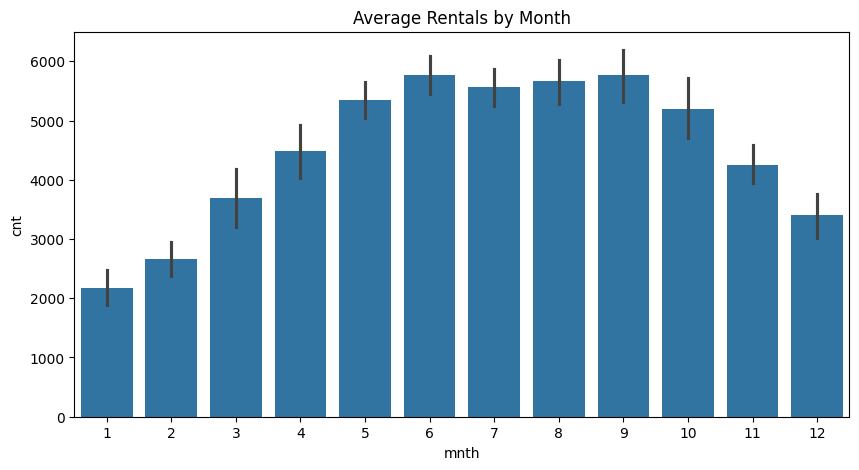

mnth
1     2176.0
2     2655.0
3     3692.0
4     4485.0
5     5350.0
6     5772.0
7     5564.0
8     5664.0
9     5767.0
10    5199.0
11    4247.0
12    3404.0
Name: cnt, dtype: float64


In [27]:
plt.figure(figsize=(10, 5))
sns.barplot(data=day, x='mnth', y='cnt')
plt.title("Average Rentals by Month")
plt.show()

print(day.groupby('mnth')['cnt'].mean().round(0))

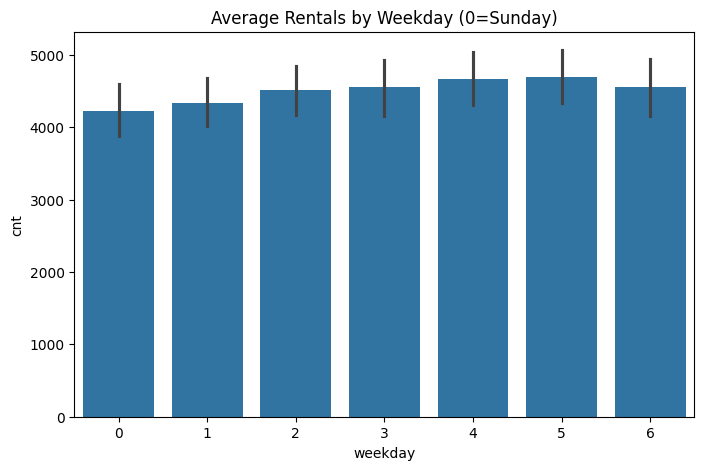

workingday
0    4330.0
1    4585.0
Name: cnt, dtype: float64
holiday
0    4527.0
1    3735.0
Name: cnt, dtype: float64


In [28]:
plt.figure(figsize=(8, 5))
sns.barplot(data=day, x='weekday', y='cnt')
plt.title("Average Rentals by Weekday (0=Sunday)")
plt.show()

print(day.groupby('workingday')['cnt'].mean().round(0))
print(day.groupby('holiday')['cnt'].mean().round(0))

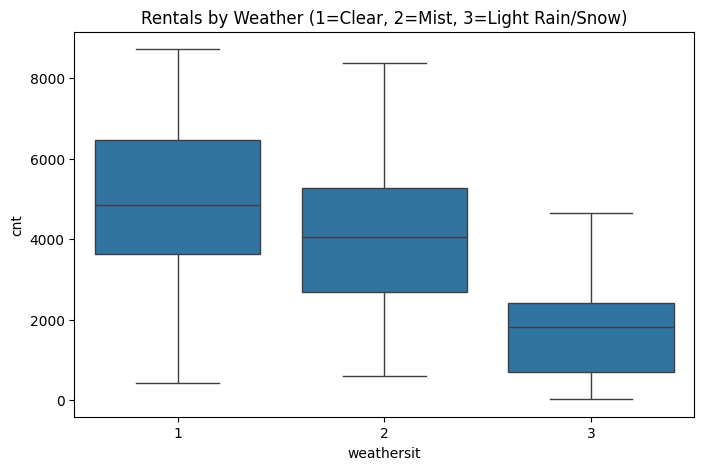

              mean  count
weathersit               
1           4877.0    463
2           4036.0    247
3           1803.0     21


In [29]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=day, x='weathersit', y='cnt')
plt.title("Rentals by Weather (1=Clear, 2=Mist, 3=Light Rain/Snow)")
plt.show()

print(day.groupby('weathersit')['cnt'].agg(['mean', 'count']).round(0))

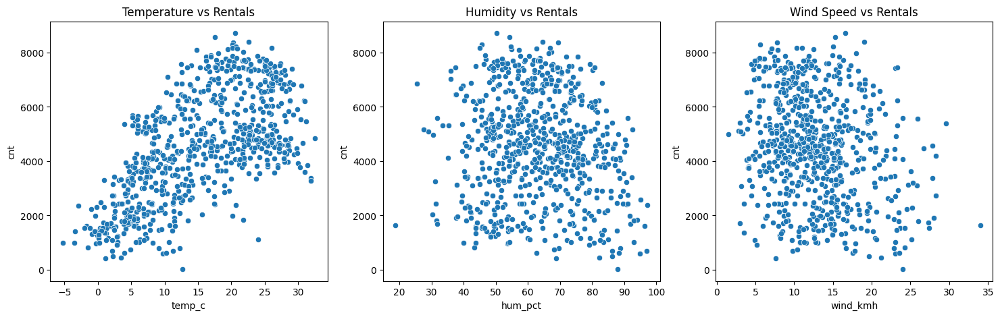

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=day, x='temp_c', y='cnt', ax=axes[0])
axes[0].set_title("Temperature vs Rentals")

sns.scatterplot(data=day, x='hum_pct', y='cnt', ax=axes[1])
axes[1].set_title("Humidity vs Rentals")

sns.scatterplot(data=day, x='wind_kmh', y='cnt', ax=axes[2])
axes[2].set_title("Wind Speed vs Rentals")

plt.show()

Registered share: 81.2%
            casual  registered
workingday                    
0           1371.0      2959.0
1            607.0      3978.0


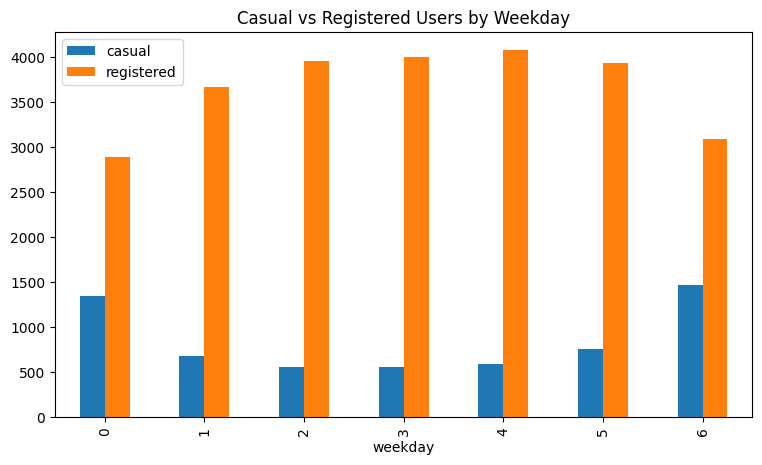

In [31]:
print("Registered share: {:.1f}%".format(100 * day['registered'].sum() / day['cnt'].sum()))

print(day.groupby('workingday')[['casual', 'registered']].mean().round(0))

day.groupby('weekday')[['casual', 'registered']].mean().plot(kind='bar', figsize=(9, 5))
plt.title("Casual vs Registered Users by Weekday")
plt.show()

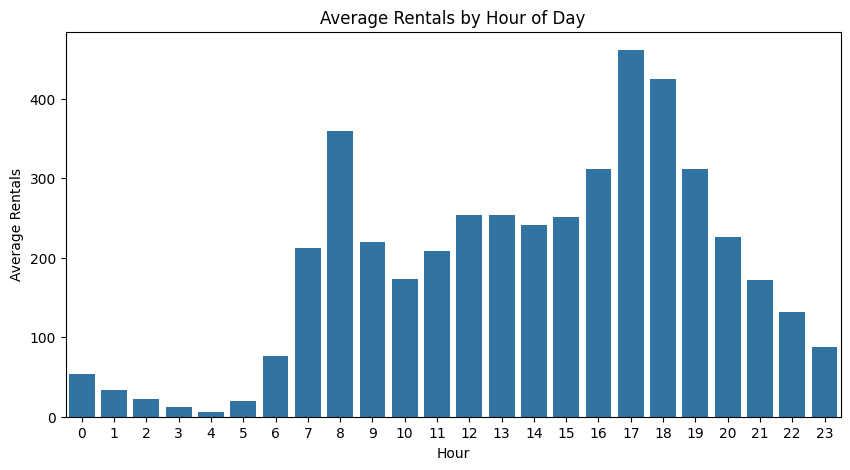

hr
0      54.0
1      33.0
2      23.0
3      12.0
4       6.0
5      20.0
6      76.0
7     212.0
8     359.0
9     219.0
10    174.0
11    208.0
12    253.0
13    254.0
14    241.0
15    251.0
16    312.0
17    461.0
18    426.0
19    312.0
20    226.0
21    172.0
22    131.0
23     88.0
Name: cnt, dtype: float64


In [32]:
hourly_avg = hour.groupby('hr')['cnt'].mean()

plt.figure(figsize=(10, 5))
sns.barplot(x=hourly_avg.index, y=hourly_avg.values)
plt.title("Average Rentals by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Average Rentals")
plt.show()

print(hourly_avg.round(0))

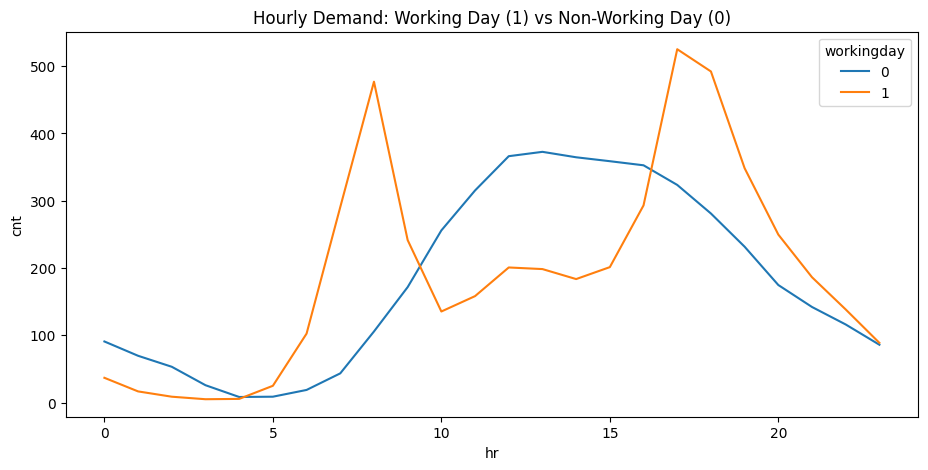

Peak hour on working days    : 17
Peak hour on non-working days: 13


In [33]:
plt.figure(figsize=(11, 5))
sns.lineplot(data=hour, x='hr', y='cnt', hue='workingday', estimator='mean', errorbar=None)
plt.title("Hourly Demand: Working Day (1) vs Non-Working Day (0)")
plt.show()

print("Peak hour on working days    :", hour[hour['workingday'] == 1].groupby('hr')['cnt'].mean().idxmax())
print("Peak hour on non-working days:", hour[hour['workingday'] == 0].groupby('hr')['cnt'].mean().idxmax())

In [34]:
print(hour.groupby('weathersit')['cnt'].mean().round(0))
print(hour[['temp', 'atemp', 'hum', 'windspeed', 'hr', 'cnt']].corr()['cnt'].round(3))

weathersit
1    205.0
2    175.0
3    112.0
4     74.0
Name: cnt, dtype: float64
temp         0.405
atemp        0.401
hum         -0.323
windspeed    0.093
hr           0.394
cnt          1.000
Name: cnt, dtype: float64


## Outliers

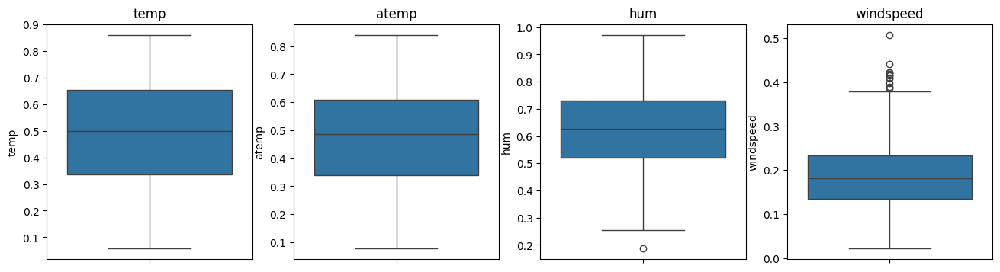

cnt outliers: 0
temp outliers: 0
hum outliers: 1
windspeed outliers: 13
casual outliers: 44
registered outliers: 0


In [35]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ['temp', 'atemp', 'hum', 'windspeed']):
    sns.boxplot(y=day[col], ax=ax)
    ax.set_title(col)
plt.show()

def count_outliers(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

for col in ['cnt', 'temp', 'hum', 'windspeed', 'casual', 'registered']:
    print(col, "outliers:", count_outliers(day[col]))

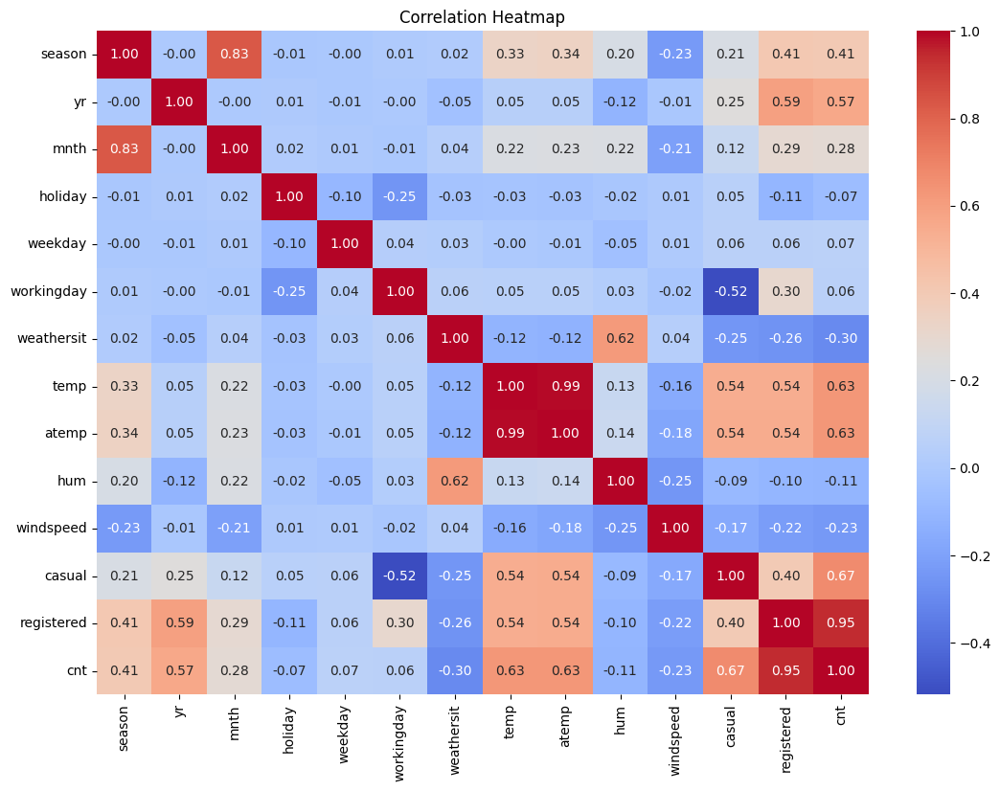

cnt           1.000
registered    0.946
casual        0.673
atemp         0.631
temp          0.627
yr            0.567
season        0.406
mnth          0.280
weekday       0.067
workingday    0.061
holiday      -0.068
hum          -0.114
windspeed    -0.235
weathersit   -0.297
Name: cnt, dtype: float64

temp vs atemp correlation: 0.9917015532294641


In [36]:
corr_cols = ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit',
             'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

plt.figure(figsize=(13, 9))
sns.heatmap(day[corr_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

print(day[corr_cols].corr()['cnt'].sort_values(ascending=False).round(3))
print("\ntemp vs atemp correlation:", day['temp'].corr(day['atemp']))

## Key Insights from the Data Analysis
- **Growth:** average daily rentals rose from about 3,406 (2011) to about 5,600 (2012), a rise of about 64%.
- **Season:** summer is busiest (about 5,644/day), followed by spring (about 4,992) and fall (about 4,728); winter is lowest (about 2,604). By month, June to September are the peak and January is the lowest (about 2,176).
- **Weather:** clear days average about 4,877 rentals, misty days about 4,036, and light rain/snow days only about 1,803.
- **Temperature:** the strongest weather factor (correlation about 0.63). `temp` and `atemp` are 0.99 correlated, so they carry the same information.
- **Users:** registered users make up about 81% of rentals. They dominate working days (about 3,978 vs 607 casual), while casual users more than double on non-working days (about 1,371).
- **Hourly pattern:** working days have commuter peaks at 8 AM and 5-6 PM; non-working days have one smooth afternoon peak.
- **Data quality:** no missing values or duplicates; one day has humidity of 0, which was replaced with the median.
- **Outliers:** 13 in wind speed and 44 in casual users; they were kept because they are real events.

## Prepare data for modelling

In [37]:
X = day.drop(['instant', 'dteday', 'casual', 'registered', 'atemp', 'cnt',
              'temp_c', 'hum_pct', 'wind_kmh', 'year'], axis=1)
y = day['cnt']

X = pd.get_dummies(X, columns=['season', 'mnth', 'weekday', 'weathersit'],
                   drop_first=True, dtype=int)

print("Features shape:", X.shape)
print(X.columns.tolist())

Features shape: (731, 28)
['yr', 'holiday', 'workingday', 'temp', 'hum', 'windspeed', 'season_2', 'season_3', 'season_4', 'mnth_2', 'mnth_3', 'mnth_4', 'mnth_5', 'mnth_6', 'mnth_7', 'mnth_8', 'mnth_9', 'mnth_10', 'mnth_11', 'mnth_12', 'weekday_1', 'weekday_2', 'weekday_3', 'weekday_4', 'weekday_5', 'weekday_6', 'weathersit_2', 'weathersit_3']


In [38]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Training: (584, 28)
Testing : (147, 28)


## Train and compare models

In [39]:
models = {
    'Linear Regression': (LinearRegression(), True),
    'KNN': (KNeighborsRegressor(n_neighbors=7), True),
    'SVR': (SVR(C=3000, epsilon=100), True),
    'Decision Tree': (DecisionTreeRegressor(max_depth=6, random_state=42), False),
    'Random Forest': (RandomForestRegressor(n_estimators=300, random_state=42), False),
    'Gradient Boosting': (GradientBoostingRegressor(n_estimators=200, learning_rate=0.05,
                                                    max_depth=3, random_state=42), False),
}

rows = []
for name, (model, needs_scaling) in models.items():
    if needs_scaling:
        Xtr, Xte = X_train_scaled, X_test_scaled
    else:
        Xtr, Xte = X_train, X_test

    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    cv = cross_val_score(model, Xtr, y_train, cv=5, scoring='r2')

    rows.append([name,
                 r2_score(y_train, model.predict(Xtr)),
                 r2_score(y_test, pred),
                 cv.mean(),
                 mean_absolute_error(y_test, pred),
                 np.sqrt(mean_squared_error(y_test, pred))])
    print(name, "done")

results = pd.DataFrame(rows, columns=['Model', 'Train R2', 'Test R2', 'CV R2', 'MAE', 'RMSE'])
results = results.sort_values('Test R2', ascending=False).round(3)
results

Linear Regression done
KNN done
SVR done
Decision Tree done
Random Forest done
Gradient Boosting done


,Model,Train R2,Test R2,CV R2,MAE,RMSE
5,Gradient Boosting,0.950,0.893,0.866,469.941,654.206
4,Random Forest,0.981,0.874,0.842,469.900,709.902
2,SVR,0.947,0.872,0.839,523.914,716.048
0,Linear Regression,0.847,0.840,0.817,586.438,800.695
3,Decision Tree,0.911,0.755,0.737,652.026,990.536
1,KNN,0.635,0.616,0.542,1060.765,1240.814


In [40]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [2, 3, 4]
}

grid = GridSearchCV(GradientBoostingRegressor(random_state=42),
                    param_grid, cv=5, scoring='r2', n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV R2:", round(grid.best_score_, 4))

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print("Test R2  :", round(r2_score(y_test, y_pred), 4))
print("Test MAE :", round(mean_absolute_error(y_test, y_pred), 1))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 1))

Best parameters: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 300}
Best CV R2: 0.8729
Test R2  : 0.8983
Test MAE : 452.9
Test RMSE: 638.7


## Checking the predictions

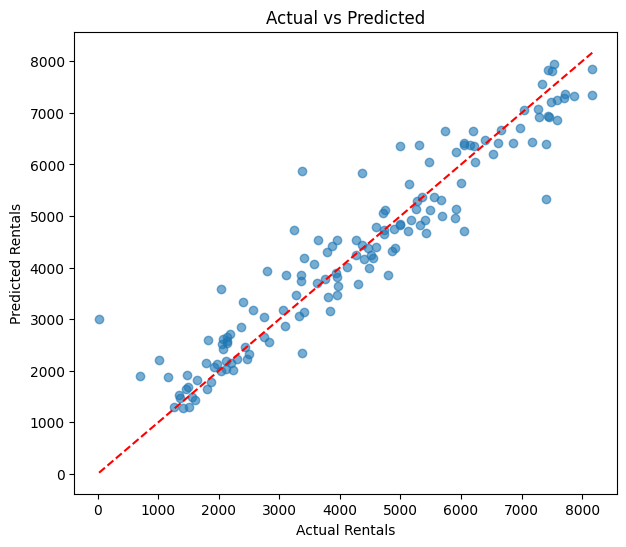

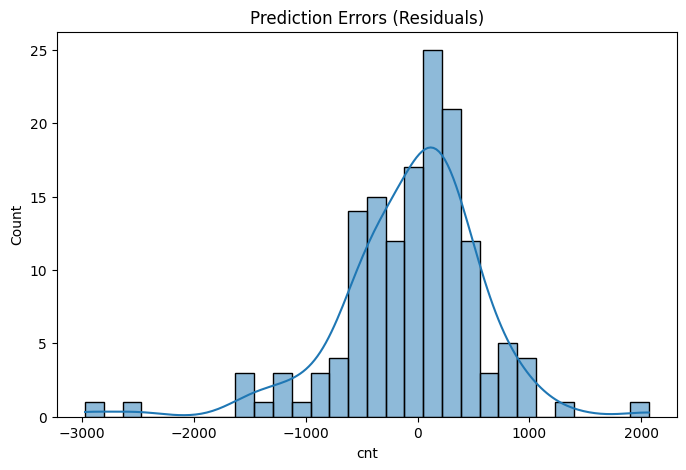

Average error: -58.8


In [41]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual Rentals")
plt.ylabel("Predicted Rentals")
plt.title("Actual vs Predicted")
plt.show()

residuals = y_test - y_pred
plt.figure(figsize=(8, 5))
sns.histplot(residuals, bins=30, kde=True)
plt.title("Prediction Errors (Residuals)")
plt.show()
print("Average error:", round(residuals.mean(), 1))

temp            0.511
yr              0.294
hum             0.065
season_4        0.049
windspeed       0.029
weathersit_3    0.016
workingday      0.007
mnth_9          0.005
dtype: float64


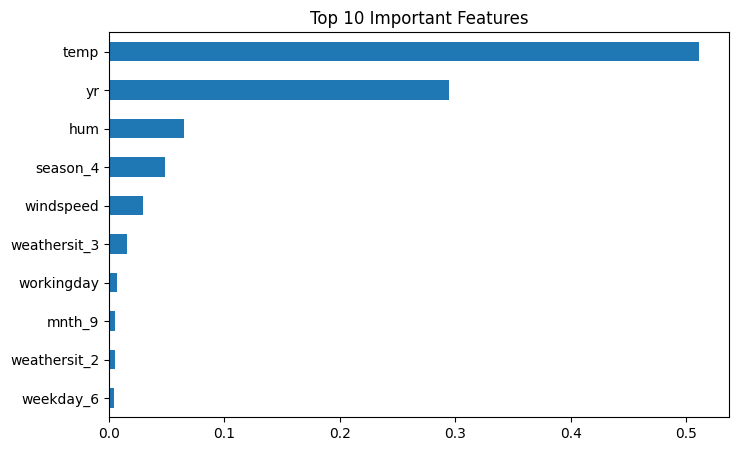

In [42]:
importance = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importance.head(8).round(3))

importance.head(10).sort_values().plot(kind='barh', figsize=(8, 5))
plt.title("Top 10 Important Features")
plt.show()

## Model Comparison Report

Six models were compared on the daily data using the same 80/20 split and 5-fold cross-validation.

| Model | Test R2 | CV R2 | MAE |
|---|---|---|---|
| Gradient Boosting | 0.893 | 0.866 | 470 |
| Random Forest | 0.874 | 0.842 | 470 |
| SVR | 0.872 | 0.839 | 524 |
| Linear Regression | 0.840 | 0.817 | 586 |
| Decision Tree | 0.755 | 0.737 | 652 |
| KNN | 0.616 | 0.542 | 1061 |

After tuning, Gradient Boosting reached Test R2 of about 0.898 with MAE of about 453 bikes/day.

**Best model for production: Gradient Boosting (tuned).**
- It has the highest test and cross-validated R2 and the lowest error.
- It captures non-linear effects (temperature, season) that Linear Regression cannot.
- Its train-test gap is smaller than Random Forest's, so it overfits less.
- Limitation: demand grows over time (2012 was about 64% higher than 2011), so the model should be retrained as new data arrives.

## Report on Challenges Faced

| Challenge | Technique used | Reasoning |
|---|---|---|
| casual + registered = cnt | Dropped both columns | They add up to the target, so using them is data leakage |
| temp and atemp are 0.99 correlated | Dropped atemp | Duplicate information, can confuse linear models |
| One day with humidity = 0 | Replaced with median humidity | Humidity cannot be 0, it is a recording error; dropping the day would lose data |
| season, mnth, weekday, weathersit are codes | Dummy variables (get_dummies) | Numbers like 1-12 imply a false order |
| Features on different scales | StandardScaler for Linear, KNN, SVR | These models are sensitive to scale; fitted on train data only to avoid leakage |
| Outliers in windspeed (13) and casual (44) | Kept them | They are real events (windy days, weekends) and tree models are robust |
| Demand grew 64% from 2011 to 2012 | Kept yr as a feature | Without it the model cannot explain the growth |
| Small dataset (731 days) | 5-fold CV, shallow trees via grid search | Shows the score is stable and prevents overfitting |
| Two files (day and hour) | Used hour.csv for hourly EDA, day.csv for modelling | Task asks for the daily count; hourly data shows the commuter pattern |
| hour.csv has missing hours | Understood that no row = no rentals | Aggregated hourly totals still match day.csv exactly |
| Weather category 4 is missing in day.csv | Kept the category list as is | Only 3 hours in hour.csv have it, too few to learn from |